# Model 3 - Transformer (text -> coarse mel)
Run the setup cell first, then **Run all**. About 1.5-3 hours on a T4 (faster on A100). It exports the coarse mels that Model 4 needs.
Needs notebooks 00 and 02.

In [1]:
!pip install -q librosa soundfile num2words


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\INTEL\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [3]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

GPU: NVIDIA GeForce RTX 4070


[transformer] starting fresh
[transformer] epoch 1/100  train=0.1883  val=0.1318  (55s)  * best
[transformer] epoch 2/100  train=0.1500  val=0.1266  (54s)  * best
[transformer] epoch 3/100  train=0.1457  val=0.1242  (53s)  * best
[transformer] epoch 4/100  train=0.1429  val=0.1235  (54s)  * best
[transformer] epoch 5/100  train=0.1410  val=0.1218  (53s)  * best
[transformer] epoch 6/100  train=0.1394  val=0.1211  (53s)  * best
[transformer] epoch 7/100  train=0.1383  val=0.1207  (53s)  * best
[transformer] epoch 8/100  train=0.1371  val=0.1202  (53s)  * best
[transformer] epoch 9/100  train=0.1364  val=0.1191  (53s)  * best
[transformer] epoch 10/100  train=0.1355  val=0.1193  (52s)
[transformer] epoch 11/100  train=0.1346  val=0.1184  (53s)  * best
[transformer] epoch 12/100  train=0.1339  val=0.1185  (53s)
[transformer] epoch 13/100  train=0.1332  val=0.1190  (53s)
[transformer] epoch 14/100  train=0.1326  val=0.1182  (53s)  * best
[transformer] epoch 15/100  train=0.1322  val=0.1181

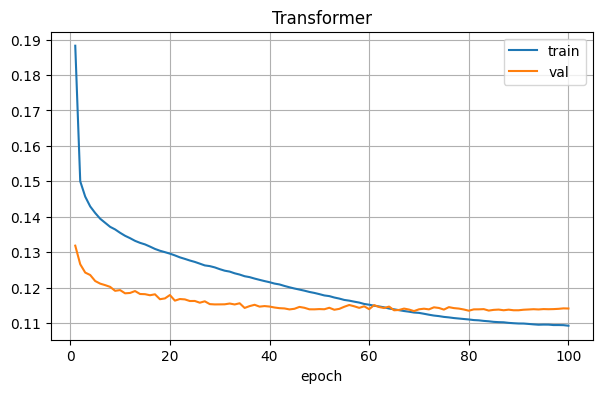

In [4]:
from vc_lib import train_transformer
from vc_lib.common import plot_history

hist = train_transformer.train(ROOT, epochs=100, batch_size=32, lr=1e-4, warmup=4000, amp=False)
plot_history(hist, ['train', 'val'], 'Transformer')

If training finished but the export was interrupted, run this cell alone:

In [ ]:
# from vc_lib import train_transformer
# train_transformer.export_coarse(ROOT)

c:\Users\INTEL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


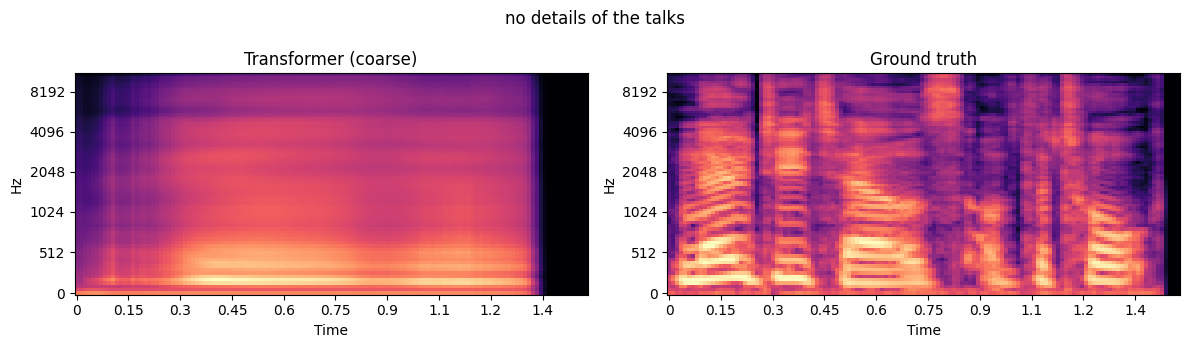

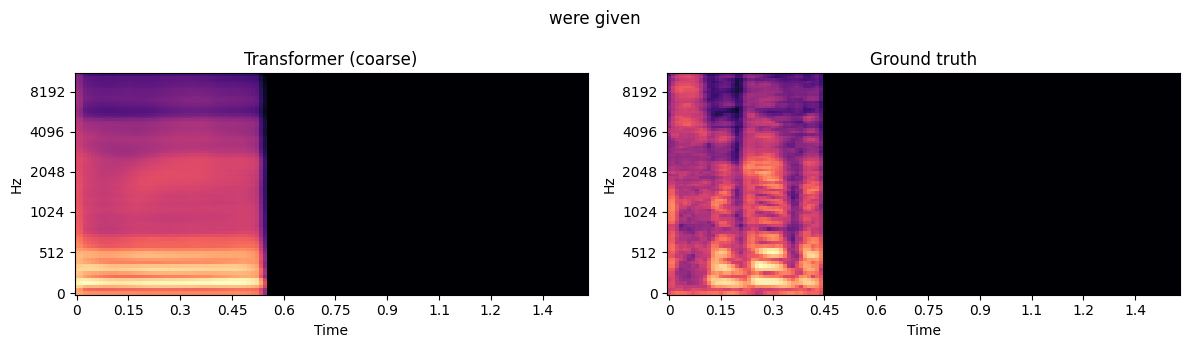

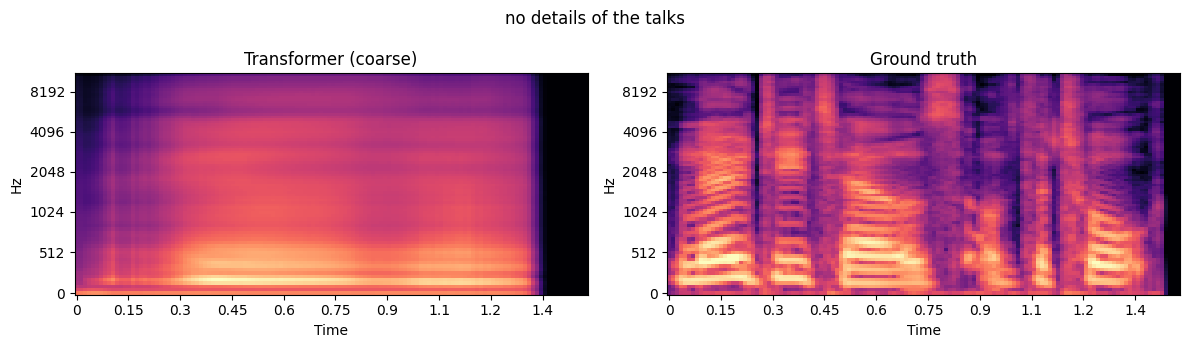

In [5]:
import torch, matplotlib.pyplot as plt, librosa.display
from vc_lib.common import paths, load_cache, tload, SR
p = paths(ROOT); C = load_cache(p); CC = tload(p['coarse'])
for i in C['idx']['val'][:3].tolist():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for a, d, t in zip(ax, [CC['coarse'][i], C['mels'][i]], ['Transformer (coarse)', 'Ground truth']):
        librosa.display.specshow(d.float().numpy(), ax=a, sr=SR, hop_length=256, x_axis='time', y_axis='mel'); a.set_title(t)
    fig.suptitle(C['texts'][i]); plt.tight_layout(); plt.show()

In [3]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
from vc_lib.common import paths, load_cache, tload

p = paths(ROOT); C = load_cache(p); CC = tload(p["coarse"])
i = C["idx"]["train"][100].item()
cm = CC["coarse"][i].float(); tm = C["mels"][i].float()

print("coarse speech bins (top 10% mean):", round(cm.flatten().topk(cm.numel()//10).values.mean().item(), 3),
      "| truth:", round(tm.flatten().topk(tm.numel()//10).values.mean().item(), 3))
print("coarse frames above 0.2:", round((cm > 0.2).float().mean().item(), 3),
      "| truth:", round((tm > 0.2).float().mean().item(), 3))

coarse speech bins (top 10% mean): 0.711 | truth: 0.791
coarse frames above 0.2: 0.824 | truth: 0.68
